# Train the sign-language models (Colab)

Trains **Random Forest, SVM and KNN** on your own recorded data.
Rules this notebook follows: models and settings are chosen on the **validation** session only; the **test** session is used **once**, at the very end, for the final model.

Before running: put the project folder `asl-sign-language` (with `src/` and `data/raw/`) in Google Drive, then run the cells from top to bottom.

In [3]:
# 1. SETUP  ------------------------------------------------------------
import os, sys, glob, time, json
import numpy as np, pandas as pd
import sklearn, joblib

try:                                   # Colab: connect Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

PROJECT_DIR = os.environ.get("ASL_PROJECT_DIR", "/content/drive/MyDrive/asl-sign-language")
RAW_DIR     = os.path.join(PROJECT_DIR, "data", "raw")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
MODELS_DIR  = os.path.join(PROJECT_DIR, "models")
os.makedirs(RESULTS_DIR, exist_ok=True); os.makedirs(MODELS_DIR, exist_ok=True)

sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
import features as F                   # the SAME file the website will use

# Which sessions are used for what (must match the plan)
TRAIN_SESSIONS = [1, 2, 3, 4]          # session 2 is skipped automatically if it is missing
VAL_SESSIONS   = [5]
TEST_SESSIONS  = [6]                   # do NOT look at this until section 6

STATIC_LETTERS = list("ABCDEFGHIKLMNOPQRSTUVWXY")
STATIC_CLASSES = STATIC_LETTERS + ["REST"]
DYNAMIC_CLASSES = ["J", "Z", "NONE"]
DYNAMIC_FRAME_RANGE = (0, 29)          # frames used from each J/Z/NONE recording

print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
print("Use these same versions on your laptop when loading the saved models.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
scikit-learn 1.6.1 | numpy 2.1.3 | pandas 2.2.3
Use these same versions on your laptop when loading the saved models.


## 2. Load the static data (24 letters + REST)

In [4]:
COORDS = [f"{c}{i}" for i in range(21) for c in "xyz"]

def session_number(path):
    return int(os.path.basename(os.path.dirname(path)).split("_")[1])

frames = []
for cls in STATIC_CLASSES:
    for path in sorted(glob.glob(os.path.join(RAW_DIR, "session_*", f"{cls}.csv"))):
        d = pd.read_csv(path)
        d["session"] = session_number(path)          # trust the folder name
        frames.append(d)

static = pd.concat(frames, ignore_index=True)
missing = [c for c in COORDS + ["label", "hand"] if c not in static.columns]
assert not missing, f"columns missing: {missing[:5]}"
assert set(static.label) <= set(STATIC_CLASSES), set(static.label) - set(STATIC_CLASSES)

print("Static samples:", len(static))
print()
print("Samples per session and hand:")
print(static.groupby(["session", "hand"]).size().unstack(fill_value=0))
print()
counts = static.groupby(["session", "label"]).size().unstack(fill_value=0)
print("Classes with fewer than 20 samples in some session (check these):")
print(counts[counts < 20].stack().to_string() if (counts < 20).any().any() else "none")

Static samples: 7500

Samples per session and hand:
hand     Left  Right
session             
1         625    625
2         625    625
3         625    625
4         625    625
5         625    625
6         625    625

Classes with fewer than 20 samples in some session (check these):
none


## 3. Split by SESSION (never by random rows - neighbouring samples look alike)

In [5]:
def split(df, sessions):
    return df[df.session.isin(sessions)].reset_index(drop=True)

tr, va, te = split(static, TRAIN_SESSIONS), split(static, VAL_SESSIONS), split(static, TEST_SESSIONS)
print("train", len(tr), "| validation", len(va), "| test", len(te), "(test is NOT used until section 6)")
assert len(tr) and len(va), "need training and validation data"

def build(df, kind):
    X = np.array([F.static_features(r[COORDS].to_numpy(float), r["hand"], kind) for _, r in df.iterrows()])
    return X, df.label.to_numpy()

train 5000 | validation 1250 | test 1250 (test is NOT used until section 6)


## 4. Compare feature sets and models on the VALIDATION session

Four feature sets x three models, each with a small settings grid. Everything is judged on **macro F1** (every letter counts equally) on session 5.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

def candidates():
    for C in (1, 10, 100):
        yield "SVM", {"C": C}, lambda C=C: make_pipeline(StandardScaler(), SVC(C=C, gamma="scale"))
    for k in (3, 5, 9):
        yield "KNN", {"k": k}, lambda k=k: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    for n in (200, 400):
        yield "Random Forest", {"trees": n}, lambda n=n: RandomForestClassifier(n_estimators=n, random_state=0, n_jobs=-1)

rows = []
for kind in F.STATIC_KINDS:
    Xtr, ytr = build(tr, kind)
    Xva, yva = build(va, kind)
    for name, params, make in candidates():
        model = make().fit(Xtr, ytr)
        pred = model.predict(Xva)
        rows.append(dict(feature_set=kind, model=name, params=json.dumps(params),
                         val_accuracy=accuracy_score(yva, pred),
                         val_macro_f1=f1_score(yva, pred, average="macro")))
        print(f"{kind:17s} {name:14s} {params}  F1={rows[-1]['val_macro_f1']:.3f}")

grid = pd.DataFrame(rows)
grid.to_csv(os.path.join(RESULTS_DIR, "validation_grid.csv"), index=False)

raw               SVM            {'C': 1}  F1=0.843
raw               SVM            {'C': 10}  F1=0.870
raw               SVM            {'C': 100}  F1=0.875
raw               KNN            {'k': 3}  F1=0.698
raw               KNN            {'k': 5}  F1=0.690
raw               KNN            {'k': 9}  F1=0.681
raw               Random Forest  {'trees': 200}  F1=0.764
raw               Random Forest  {'trees': 400}  F1=0.765
norm              SVM            {'C': 1}  F1=0.891
norm              SVM            {'C': 10}  F1=0.916
norm              SVM            {'C': 100}  F1=0.921
norm              KNN            {'k': 3}  F1=0.870
norm              KNN            {'k': 5}  F1=0.866
norm              KNN            {'k': 9}  F1=0.842
norm              Random Forest  {'trees': 200}  F1=0.889
norm              Random Forest  {'trees': 400}  F1=0.890
norm_mirror       SVM            {'C': 1}  F1=0.939
norm_mirror       SVM            {'C': 10}  F1=0.947
norm_mirror       SVM            

In [7]:
# Best setting of each model (chosen on validation only)
best = grid.sort_values("val_macro_f1", ascending=False).groupby("model").head(1).reset_index(drop=True)

# Time for ONE prediction (one hand sample), averaged over many repeats
def time_one_ms(model, x, repeats=200):
    model.predict(x)
    t0 = time.perf_counter()
    for _ in range(repeats):
        model.predict(x)
    return (time.perf_counter() - t0) / repeats * 1000

maker = {(n, json.dumps(p)): m for n, p, m in candidates()}
times = []
for _, r in best.iterrows():
    Xtr, ytr = build(tr, r.feature_set)
    Xva, _ = build(va, r.feature_set)
    model = maker[(r.model, r.params)]().fit(Xtr, ytr)
    times.append(time_one_ms(model, Xva[:1]))
best["inference_ms"] = times

comparison = best[["model", "val_accuracy", "val_macro_f1", "inference_ms", "feature_set", "params"]]
comparison.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"), index=False)
comparison

,model,val_accuracy,val_macro_f1,inference_ms,feature_set,params
0,SVM,0.9496,0.948228,1.174970,norm_mirror,"{""C"": 100}"
1,Random Forest,0.9216,0.920271,50.663466,norm_mirror_dist,"{""trees"": 200}"
2,KNN,0.9072,0.904713,2.055985,norm_mirror_dist,"{""k"": 3}"


In [8]:
# Does the new feature processing help? (best validation F1 per feature set, per model)
print(grid.pivot_table(index="feature_set", columns="model", values="val_macro_f1", aggfunc="max").round(3))

model               KNN  Random Forest    SVM
feature_set                                  
norm              0.870          0.890  0.921
norm_mirror       0.897          0.914  0.948
norm_mirror_dist  0.905          0.920  0.946
raw               0.698          0.765  0.875


## 5. Dynamic gestures: J, Z, NONE

Uses all 5 fingertips, resampled by time (see `features.py`). Same train / validation / test sessions.

In [9]:
def load_dynamic():
    out = []
    for cls in DYNAMIC_CLASSES:
        for path in sorted(glob.glob(os.path.join(RAW_DIR, "session_*", f"{cls}.csv"))):
            d = pd.read_csv(path)
            s = session_number(path)
            lo, hi = DYNAMIC_FRAME_RANGE
            d = d[(d.frame >= lo) & (d.frame <= hi)]
            for (hand, sid), g in d.groupby(["hand", "sample_id"]):
                out.append(dict(
                    session=s, label=cls, hand=hand,
                    x=F.dynamic_features(g[COORDS].to_numpy(float), g["t"].to_numpy(float), hand)))
    return pd.DataFrame(out)

dyn = load_dynamic()
print("Dynamic samples:", len(dyn))
print(dyn.groupby(["session", "label"]).size().unstack(fill_value=0))

Dynamic samples: 1080
label     J  NONE   Z
session              
1        60    60  60
2        60    60  60
3        60    60  60
4        60    60  60
5        60    60  60
6        60    60  60


In [10]:
dtr, dva, dte = (split(dyn, s) for s in (TRAIN_SESSIONS, VAL_SESSIONS, TEST_SESSIONS))
stack = lambda d: (np.vstack(d.x.to_numpy()), d.label.to_numpy())
Xdtr, ydtr = stack(dtr); Xdva, ydva = stack(dva)

drows = []
for name, params, make in candidates():
    model = make().fit(Xdtr, ydtr)
    pred = model.predict(Xdva)
    drows.append(dict(model=name, params=json.dumps(params),
                      val_accuracy=accuracy_score(ydva, pred),
                      val_macro_f1=f1_score(ydva, pred, average="macro")))
dgrid = pd.DataFrame(drows)
dbest = dgrid.sort_values("val_macro_f1", ascending=False).groupby("model").head(1)
dgrid.to_csv(os.path.join(RESULTS_DIR, "validation_grid_dynamic.csv"), index=False)
dbest

,model,params,val_accuracy,val_macro_f1
1,SVM,"{""C"": 10}",0.988889,0.988889
6,Random Forest,"{""trees"": 200}",0.972222,0.972205
3,KNN,"{""k"": 3}",0.966667,0.966630


## 6. FINAL TEST - run this ONCE

The best model (highest validation macro F1) is refitted on training + validation sessions and tested a single time on the unseen test session. If you change anything after looking at these numbers, the test result is no longer honest.

In [11]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

assert len(te) and len(dte), "test session data not found"

# ---- static ----
win = comparison.sort_values("val_macro_f1", ascending=False).iloc[0]
print("Chosen static model:", win.model, win.params, "| features:", win.feature_set)
Xtv, ytv = build(pd.concat([tr, va]), win.feature_set)
Xte, yte = build(te, win.feature_set)
static_model = maker[(win.model, win.params)]().fit(Xtv, ytv)
pred_static = static_model.predict(Xte)

# ---- dynamic ----
dwin = dbest.sort_values("val_macro_f1", ascending=False).iloc[0]
print("Chosen dynamic model:", dwin.model, dwin.params)
Xdtv, ydtv = stack(pd.concat([dtr, dva])); Xdte, ydte = stack(dte)
dmaker = {(n, json.dumps(p)): m for n, p, m in candidates()}
dyn_model = dmaker[(dwin.model, dwin.params)]().fit(Xdtv, ydtv)
pred_dyn = dyn_model.predict(Xdte)

print()
print("STATIC test accuracy :", round(accuracy_score(yte, pred_static), 4),
      "| macro F1:", round(f1_score(yte, pred_static, average="macro"), 4))
print("DYNAMIC test accuracy:", round(accuracy_score(ydte, pred_dyn), 4),
      "| macro F1:", round(f1_score(ydte, pred_dyn, average="macro"), 4))
print()
print("Static accuracy by hand:")
print(pd.Series(pred_static == yte).groupby(te.hand.to_numpy()).mean().round(4).to_string())

Chosen static model: SVM {"C": 100} | features: norm_mirror
Chosen dynamic model: SVM {"C": 10}

STATIC test accuracy : 0.9352 | macro F1: 0.9338
DYNAMIC test accuracy: 0.9833 | macro F1: 0.9834

Static accuracy by hand:
Left     0.9232
Right    0.9472


              precision    recall  f1-score   support

           A      1.000     1.000     1.000        50
           B      1.000     0.980     0.990        50
           C      1.000     1.000     1.000        50
           D      1.000     0.920     0.958        50
           E      0.979     0.920     0.948        50
           F      0.980     0.980     0.980        50
           G      0.961     0.980     0.970        50
           H      0.979     0.940     0.959        50
           I      1.000     1.000     1.000        50
           K      0.860     0.860     0.860        50
           L      1.000     0.960     0.980        50
           M      0.979     0.920     0.948        50
           N      0.961     0.980     0.970        50
           O      0.962     1.000     0.980        50
           P      0.862     0.500     0.633        50
           Q      0.648     0.920     0.760        50
           R      0.923     0.960     0.941        50
        REST      0.822    

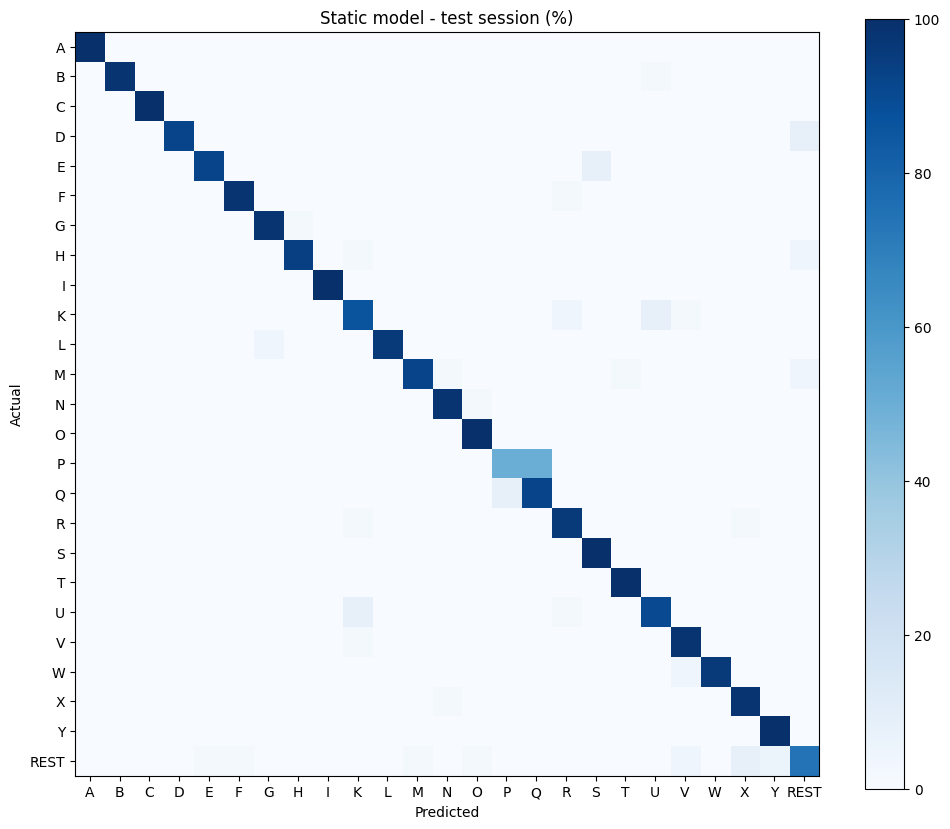

In [12]:
# Per-class precision / recall / F1 and confusion matrices
print(classification_report(yte, pred_static, digits=3, zero_division=0))
print(classification_report(ydte, pred_dyn, digits=3, zero_division=0))

report = pd.DataFrame(classification_report(
    np.concatenate([yte, ydte]), np.concatenate([pred_static, pred_dyn]),
    output_dict=True, zero_division=0)).T
report.to_csv(os.path.join(RESULTS_DIR, "per_class_report.csv"))

labels = STATIC_CLASSES
cm = confusion_matrix(yte, pred_static, labels=labels)
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1) * 100
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title("Static model - test session (%)")
plt.colorbar(im); plt.show()

In [13]:
# Save the files the poster script and the website need
pd.DataFrame({"y_true": np.concatenate([yte, ydte]),
              "y_pred": np.concatenate([pred_static, pred_dyn])}
             ).to_csv(os.path.join(RESULTS_DIR, "test_predictions.csv"), index=False)

meta = dict(sklearn=sklearn.__version__, numpy=np.__version__)
joblib.dump(dict(model=static_model, feature_kind=win.feature_set,
                 classes=list(static_model.classes_), versions=meta),
            os.path.join(MODELS_DIR, "static_model.joblib"))
joblib.dump(dict(model=dyn_model, steps=F.DYNAMIC_STEPS, frame_range=DYNAMIC_FRAME_RANGE,
                 classes=list(dyn_model.classes_), versions=meta),
            os.path.join(MODELS_DIR, "dynamic_model.joblib"))
print("Saved to", RESULTS_DIR, "and", MODELS_DIR)

Saved to /content/drive/MyDrive/asl-sign-language/results and /content/drive/MyDrive/asl-sign-language/models


## 7. After this notebook
1. Download `results/` and `models/` from Drive into your PyCharm project (same folder names).
2. `python make_poster_figures.py` makes the poster figures from `results/`.
3. `results/live_trials.csv` and `results/nlp_eval.csv` come from your live webcam trials and the NLP test (see the poster script for the format).
4. On your laptop use the same scikit-learn / numpy versions printed in section 1.